# Dataset Cleaning for Coaches


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.stats import iqr


coaches = pd.read_csv("../basketballPlayoffs/coaches.csv")
coachesy11 = pd.read_csv("../basketballPlayoffs/Season_11/coaches.csv")


merged_coaches = pd.concat([coaches, coachesy11], ignore_index=True)
merged_coaches.to_csv("../basketballPlayoffs/y11_coaches.csv", index=False)
coaches = pd.read_csv("../basketballPlayoffs/y11_coaches.csv")




# Check For Null Values

In [4]:
null = coaches.isnull().values.any()
nan = coaches.isna().values.any()

print(null)
print(nan)

# No Missing Values detected so no need of cleaning

True
True


# Dropping Unique Value Columns

In [5]:
for name in coaches:
    for col in coaches.columns:
        if len(coaches[col].unique()) == 1:
            coaches.drop(col, inplace=True, axis=1)
    print(f"Processed {name}: Remaining columns: {coaches.columns}")


Processed coachID: Remaining columns: Index(['coachID', 'year', 'tmID', 'stint', 'won', 'lost', 'post_wins',
       'post_losses'],
      dtype='object')
Processed year: Remaining columns: Index(['coachID', 'year', 'tmID', 'stint', 'won', 'lost', 'post_wins',
       'post_losses'],
      dtype='object')
Processed tmID: Remaining columns: Index(['coachID', 'year', 'tmID', 'stint', 'won', 'lost', 'post_wins',
       'post_losses'],
      dtype='object')
Processed lgID: Remaining columns: Index(['coachID', 'year', 'tmID', 'stint', 'won', 'lost', 'post_wins',
       'post_losses'],
      dtype='object')
Processed stint: Remaining columns: Index(['coachID', 'year', 'tmID', 'stint', 'won', 'lost', 'post_wins',
       'post_losses'],
      dtype='object')
Processed won: Remaining columns: Index(['coachID', 'year', 'tmID', 'stint', 'won', 'lost', 'post_wins',
       'post_losses'],
      dtype='object')
Processed lost: Remaining columns: Index(['coachID', 'year', 'tmID', 'stint', 'won', 'lost'

# Dealing with Redundancy

In [6]:

row_count = coaches.shape[0]
coaches.drop_duplicates(inplace=True)
afterDups_count = coaches.shape[0]
rows_deleted = row_count - afterDups_count
print(f"Number of rows deleted: {rows_deleted}")


Number of rows deleted: 0


# Dealing With Outliers

`# https://www.askpython.com/python/examples/how-to-determine-outlier`

# Z-Score Implementation

/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3666/2811588613.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3666/2811588613.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3666/2811588613.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_3666/2811588613.py:12: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to

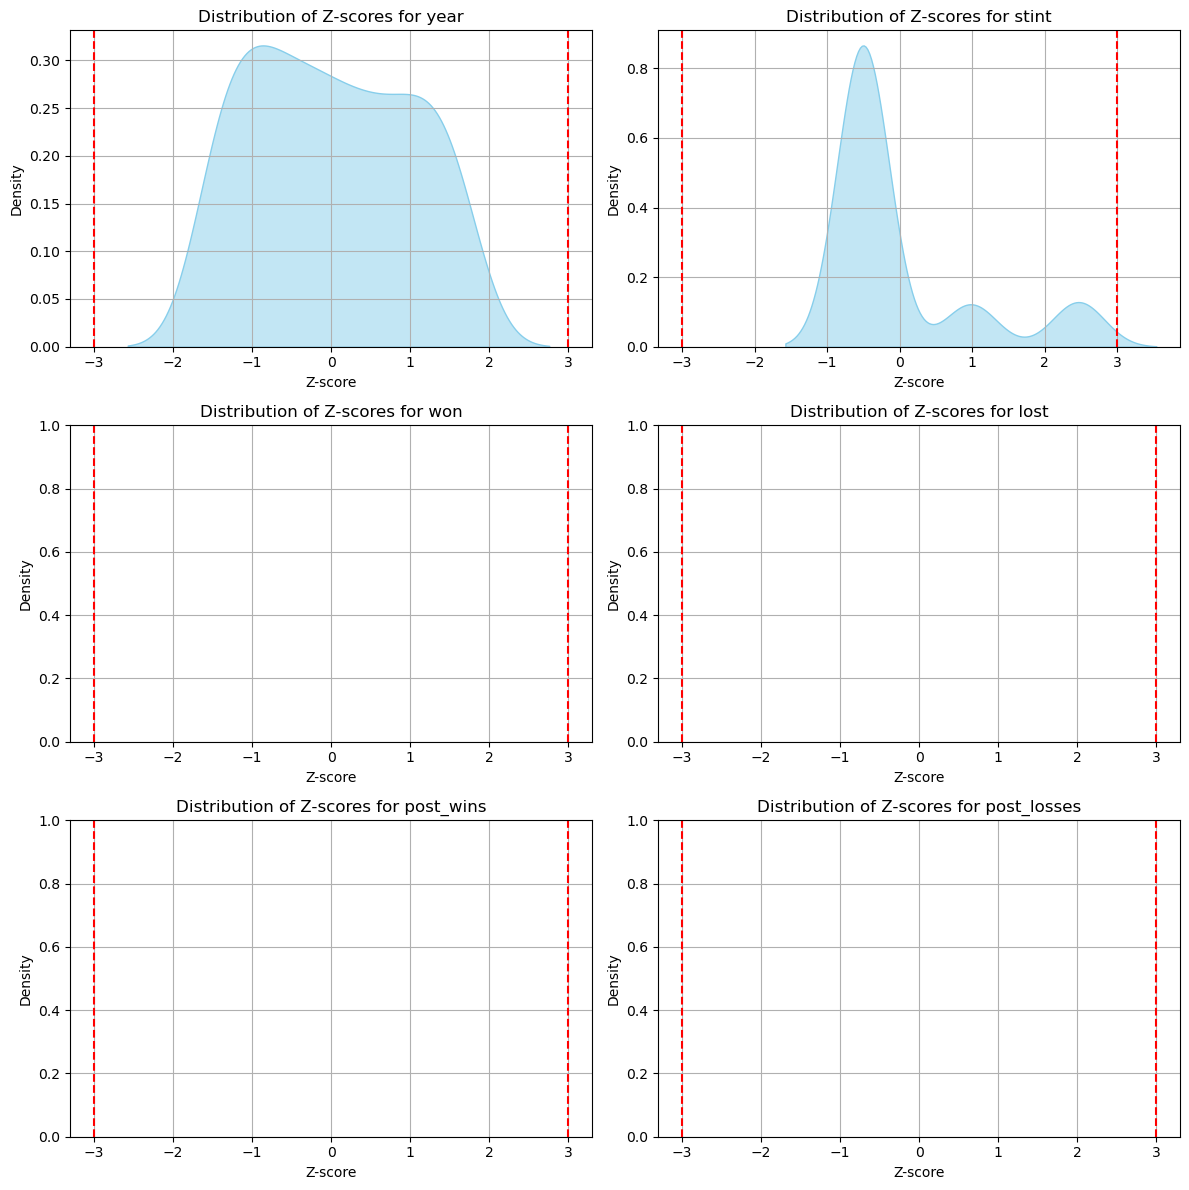

Number of outliers per column:
year           0
stint          0
won            0
lost           0
post_wins      0
post_losses    0
dtype: int64
Rows identified with any outliers: 0
Number of rows deleted: 0


In [7]:
numerical_cols = coaches.select_dtypes(['number'])
df = numerical_cols.apply(zscore)



num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))

axes = axes.flatten()
for i, column in enumerate(numerical_cols.columns):
    sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution of Z-scores for {column}')
    axes[i].set_xlabel('Z-score')
    axes[i].set_ylabel('Density')
    axes[i].grid(True)
    axes[i].axvline(x=3, color='red', linestyle='--')
    axes[i].axvline(x=-3, color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()


threshold = 3
outlier_mask = (df.abs() > threshold)
outliers_per_column = outlier_mask.sum()
print("Number of outliers per column:")
print(outliers_per_column)
rows_with_outliers = outlier_mask.any(axis=1)
print("Rows identified with any outliers:", rows_with_outliers.sum())


df_no_outliers = df[~rows_with_outliers]
num_rows_deleted = df.shape[0] - df_no_outliers.shape[0]
print(f"Number of rows deleted: {num_rows_deleted}")




# Interquartile Range Implementation

IQR for year: 5.0
IQR for won: nan
IQR for post_losses: nan


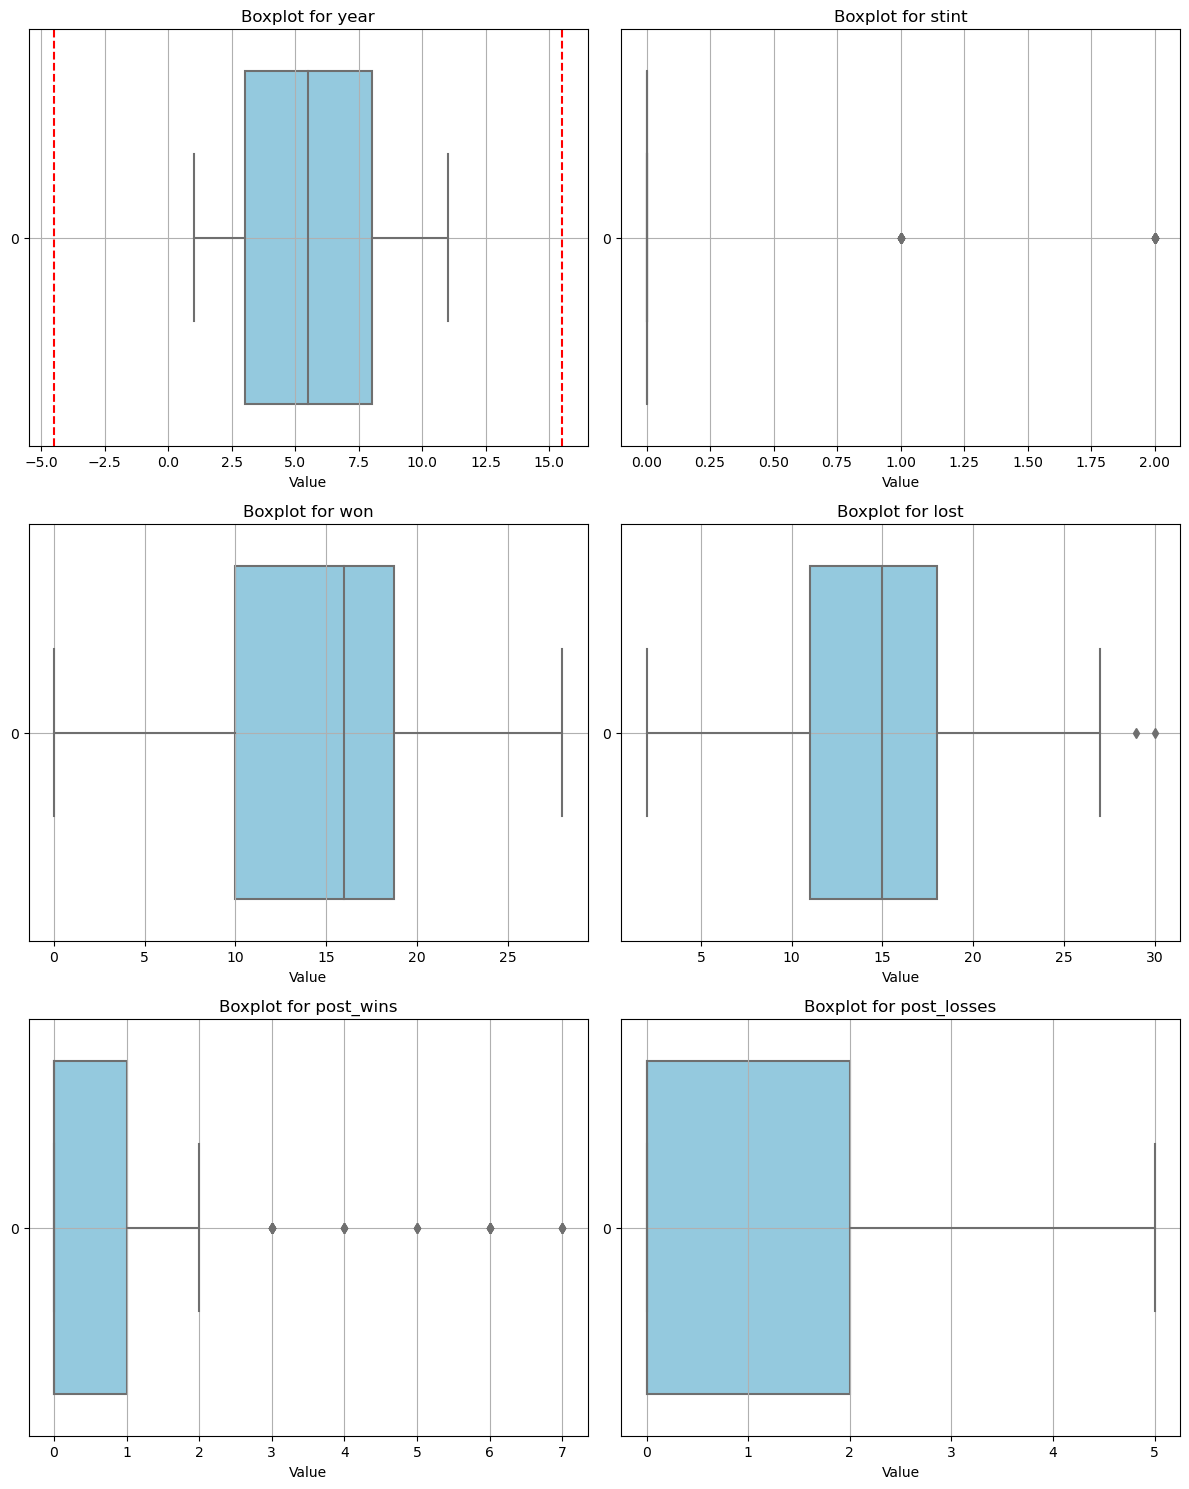

Number of outliers per column:
year           0
stint          0
won            0
lost           0
post_wins      0
post_losses    0
dtype: int64
Total number of rows with outliers: 0
Number of rows deleted: 0


In [8]:
from scipy.stats import iqr
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns, including the ones to be excluded from outlier detection
numerical_cols = coaches.select_dtypes(include='number')

# Calculate IQR for each column (excluding 'stint', 'lost', 'post_wins')
iqr_values = {}
for column in numerical_cols.columns:
    if column not in ['stint', 'lost', 'post_wins']:
        iqr_values[column] = iqr(coaches[column])
        print(f"IQR for {column}: {iqr_values[column]}")

# Define the outlier bounds and mask for outlier detection (excluding specific columns)
factor = 1.5
outlier_mask = pd.DataFrame(False, index=coaches.index, columns=numerical_cols.columns)
for column in numerical_cols.columns:
    if column not in ['stint', 'lost', 'post_wins']:
        q1 = coaches[column].quantile(0.25)
        q3 = coaches[column].quantile(0.75)
        iqr_value = iqr_values[column]
        lower_bound = q1 - factor * iqr_value
        upper_bound = q3 + factor * iqr_value
        outlier_mask[column] = (coaches[column] < lower_bound) | (coaches[column] > upper_bound)

# Plot boxplots for all numerical columns
num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_cols.columns):
    sns.boxplot(data=coaches[column], ax=axes[i], color='skyblue', orient='h')
    
    # Adding dotted red lines for IQR bounds (Q1 - 1.5*IQR and Q3 + 1.5*IQR)
    if column not in ['stint', 'lost', 'post_wins']:  # Only for columns used for outlier detection
        q1 = coaches[column].quantile(0.25)
        q3 = coaches[column].quantile(0.75)
        iqr_value = iqr_values[column]
        lower_bound = q1 - factor * iqr_value
        upper_bound = q3 + factor * iqr_value
        
        axes[i].axvline(x=lower_bound, color='red', linestyle='--', label=f'Lower Bound ({lower_bound:.2f})')
        axes[i].axvline(x=upper_bound, color='red', linestyle='--', label=f'Upper Bound ({upper_bound:.2f})')

    axes[i].set_title(f'Boxplot for {column}')
    axes[i].set_xlabel('Value')
    axes[i].grid(True)

# Hide axes for empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Count and remove outliers based on the mask
num_outliers_per_column = outlier_mask.sum()
total_outliers = outlier_mask.any(axis=1).sum()
coaches_cleaned = coaches[~outlier_mask.any(axis=1)]

print("Number of outliers per column:")
print(num_outliers_per_column)
print("Total number of rows with outliers:", total_outliers)
print("Number of rows deleted:", len(coaches) - len(coaches_cleaned))


# Create Clean CSV

In [9]:
coaches.to_csv('../cleaned_datasets/coaches_cleaned.csv', index=False)